# NLP on IMDB reviews

In [1]:
import pandas as pd 
import numpy as np

# 1. Data Collection

In [3]:
df_data=pd.read_csv('IMDB Dataset.csv')
print(df_data.shape)
print(df_data.head())

(50000, 2)
                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive


In [5]:
#df_data['review'][0]

In [7]:
len(df_data['review'][0])

1761

In [9]:
df_data['sentiment'].unique()

array(['positive', 'negative'], dtype=object)

In [9]:
df_data['sentiment'].value_counts()

sentiment
positive    25000
negative    25000
Name: count, dtype: int64

# 2. Data preprocessing and Normilization

In [11]:
df_review=df_data['review']
df_sent=df_data['sentiment']

In [13]:
def lowercase_text(text):
    # Convert text to lowercase.
    return str(text).lower()
df_review=df_review.apply(lowercase_text)

In [15]:
df_review[0]

"one of the other reviewers has mentioned that after watching just 1 oz episode you'll be hooked. they are right, as this is exactly what happened with me.<br /><br />the first thing that struck me about oz was its brutality and unflinching scenes of violence, which set in right from the word go. trust me, this is not a show for the faint hearted or timid. this show pulls no punches with regards to drugs, sex or violence. its is hardcore, in the classic use of the word.<br /><br />it is called oz as that is the nickname given to the oswald maximum security state penitentary. it focuses mainly on emerald city, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. em city is home to many..aryans, muslims, gangstas, latinos, christians, italians, irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />i would say the main appeal of the show is due to the fa

In [17]:
import re
def replace_urls(text):
    """
    Replace URLs in text with a placeholder.
    In NLP, we might want to remove URLs to:
        Reduce noise - URLs rarely add semantic meaning.
        Improve model performance - Less irrelevant data = better learning.
        Normalize text - Keeps data consistent and clean.
    """
    # Regular expression pattern to match URLs
    # This pattern matches:
    # - http:// or https:// at the beginning
    # - Followed by any combination of:
    #   - Letters (a-z, A-Z)
    #   - Numbers (0-9)
    #   - Special characters like $-_@.&+
    #   - Escaped characters like !*()
    #   - URL-encoded characters (e.g., %20 for space)
    # The + at the end ensures we match one or more of these characters
    url_pattern = r'http[s]?://(?:[a-zA-Z]|[0-9]|[$-_@.&+]|[!*\\(\\),]|(?:%[0-9a-fA-F][0-9a-fA-F]))+'

    # Replace URLs with placeholder
    return re.sub(url_pattern, 'url', str(text))

# Apply URL replacement to all summaries
df_review = df_review.apply(replace_urls)
print(df_review[0])
print(len(df_review[0]))

one of the other reviewers has mentioned that after watching just 1 oz episode you'll be hooked. they are right, as this is exactly what happened with me.<br /><br />the first thing that struck me about oz was its brutality and unflinching scenes of violence, which set in right from the word go. trust me, this is not a show for the faint hearted or timid. this show pulls no punches with regards to drugs, sex or violence. its is hardcore, in the classic use of the word.<br /><br />it is called oz as that is the nickname given to the oswald maximum security state penitentary. it focuses mainly on emerald city, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. em city is home to many..aryans, muslims, gangstas, latinos, christians, italians, irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />i would say the main appeal of the show is due to the fac

In [19]:
emoji_pattern = re.compile("["

    # Emoticons (e.g., 😀😁😂🤣😃😄😅😆)
    u"\U0001F600-\U0001F64F"

    # Symbols & pictographs (e.g., 🔥🎉💡📦📱)
    u"\U0001F300-\U0001F5FF"

    # Transport & map symbols (e.g., 🚗✈️🚀🚉)
    u"\U0001F680-\U0001F6FF"

    # Flags (e.g., 🇺🇸🇬🇧🇨🇦 — these are pairs of regional indicators)
    u"\U0001F1E0-\U0001F1FF"

    # Dingbats (e.g., ✂️✈️✉️⚽)
    u"\u2700-\u27BF"

    # Supplemental Symbols & Pictographs (e.g., 🤖🥰🧠🦾)
    u"\U0001F900-\U0001F9FF"

    # Symbols & Pictographs Extended-A (e.g., 🪄🪅🪨)
    u"\U0001FA70-\U0001FAFF"

    # Miscellaneous symbols (e.g., ☀️☁️☂️⚡)
    u"\u2600-\u26FF"

    "]+", flags=re.UNICODE)

In [21]:
emoticon_pattern = re.compile(r'(:\)|:|:D|:P|;|:D|:P|;|:-\)|:-D|:-P|:\'\(|:\||:\*)')

In [23]:
def remove_and_print(text):
    if emoji_pattern.search(text) or emoticon_pattern.search(text):
        #print(text)
        text = emoji_pattern.sub('', text)
        text = emoticon_pattern.sub('', text)
        #print(text)
    return text

In [25]:
df_review = df_review.apply(remove_and_print)
print(df_review[0])
print(len(df_review[0]))

one of the other reviewers has mentioned that after watching just 1 oz episode you'll be hooked. they are right, as this is exactly what happened with me.<br /><br />the first thing that struck me about oz was its brutality and unflinching scenes of violence, which set in right from the word go. trust me, this is not a show for the faint hearted or timid. this show pulls no punches with regards to drugs, sex or violence. its is hardcore, in the classic use of the word.<br /><br />it is called oz as that is the nickname given to the oswald maximum security state penitentary. it focuses mainly on emerald city, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. em city is home to many..aryans, muslims, gangstas, latinos, christians, italians, irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />i would say the main appeal of the show is due to the fac

In [27]:
def preprocess_data(text):
    #decontraction
    text = re.sub(r"won\'t", " will not", text)
    text = re.sub(r"won\'t've", " will not have", text)
    text = re.sub(r"can\'t", " can not", text)
    text = re.sub(r"don\'t", " do not", text)    
    text = re.sub(r"can\'t've", " can not have", text)
    text = re.sub(r"ma\'am", " madam", text)
    text = re.sub(r"let\'s", " let us", text)
    text = re.sub(r"ain\'t", " am not", text)
    text = re.sub(r"shan\'t", " shall not", text)
    text = re.sub(r"sha\n't", " shall not", text)
    text = re.sub(r"o\'clock", " of the clock", text)
    text = re.sub(r"y\'all", " you all", text)
    text = re.sub(r"n\'t", " not", text)
    text = re.sub(r"n\'t've", " not have", text)
    text = re.sub(r"\'re", " are", text)
    text = re.sub(r"\'s", " is", text)
    text = re.sub(r"\'d", " would", text)
    text = re.sub(r"\'d've", " would have", text)
    text = re.sub(r"\'ll", " will", text)
    text = re.sub(r"\'ll've", " will have", text)
    text = re.sub(r"\'t", " not", text)
    text = re.sub(r"\'ve", " have", text)
    text = re.sub(r"\'m", " am", text)
    text = re.sub(r"\'re", " are", text)
    return text
df_review = df_review.apply(preprocess_data)
print(df_review[0])
print('\n')
print(len(df_review[0]))

one of the other reviewers has mentioned that after watching just 1 oz episode you will be hooked. they are right, as this is exactly what happened with me.<br /><br />the first thing that struck me about oz was its brutality and unflinching scenes of violence, which set in right from the word go. trust me, this is not a show for the faint hearted or timid. this show pulls no punches with regards to drugs, sex or violence. its is hardcore, in the classic use of the word.<br /><br />it is called oz as that is the nickname given to the oswald maximum security state penitentary. it focuses mainly on emerald city, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. em city is home to many..aryans, muslims, gangstas, latinos, christians, italians, irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />i would say the main appeal of the show is due to the f

In [29]:
def replace_usernames(text):
    """
    Replace usernames (words starting with @) with a generic token.

    Usernames are personally identifiable information and not relevant for sentiment analysis.
    Replacing them with a consistent token helps reduce noise and protect privacy.
    """
    # Replace @username with [USER]
    return re.sub(r'@\w+', '[USER]', str(text))

# Apply username replacement to all review 
df_review = df_review.apply(replace_usernames)
print(df_review[0])
print(len(df_review[0]))

one of the other reviewers has mentioned that after watching just 1 oz episode you will be hooked. they are right, as this is exactly what happened with me.<br /><br />the first thing that struck me about oz was its brutality and unflinching scenes of violence, which set in right from the word go. trust me, this is not a show for the faint hearted or timid. this show pulls no punches with regards to drugs, sex or violence. its is hardcore, in the classic use of the word.<br /><br />it is called oz as that is the nickname given to the oswald maximum security state penitentary. it focuses mainly on emerald city, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. em city is home to many..aryans, muslims, gangstas, latinos, christians, italians, irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />i would say the main appeal of the show is due to the f

In [31]:
def remove_non_alphabets(text):
    """
    Remove non-alphabetic characters from text.

    Non-alphabetic characters like numbers and special symbols like #, $ etc. often add noise
    to text analysis.
    Removing them helps focus on the actual words and their meanings,
    which is more relevant for sentiment analysis.
    """
    # Keep only alphabetic characters and spaces
    return re.sub(r'[^a-zA-Z\s]', ' ', str(text))

# Apply non-alphabet removal to all summaries
df_review = df_review.apply(remove_non_alphabets)
print(df_review[0])
print(len(df_review[0]))

one of the other reviewers has mentioned that after watching just   oz episode you will be hooked  they are right  as this is exactly what happened with me  br    br   the first thing that struck me about oz was its brutality and unflinching scenes of violence  which set in right from the word go  trust me  this is not a show for the faint hearted or timid  this show pulls no punches with regards to drugs  sex or violence  its is hardcore  in the classic use of the word  br    br   it is called oz as that is the nickname given to the oswald maximum security state penitentary  it focuses mainly on emerald city  an experimental section of the prison where all the cells have glass fronts and face inwards  so privacy is not high on the agenda  em city is home to many  aryans  muslims  gangstas  latinos  christians  italians  irish and more    so scuffles  death stares  dodgy dealings and shady agreements are never far away  br    br   i would say the main appeal of the show is due to the f

In [32]:
def remove_consecutive_letters(text):
    """
    Remove consecutive repetitions of letters (more than 3) in text.

    In informal text like reviews, people often express emotions by elongating words
    (e.g., 'sooooo good', 'loooove it'). Normalizing these to a maximum of two consecutive
    occurrences helps standardize the text while preserving the emphasis.
    """
    # In the following pattern, 3 is the minimum number of consecutive occurrences of the same letter
    pattern = r'(\w)\1{3,}'

    # Replace with just two occurrences of the letter
    return re.sub(pattern, r'\1\1', str(text))

# Apply consecutive letter removal to all summaries
df_review = df_review.apply(remove_consecutive_letters)
print(df_review[0])
print(len(df_review[0]))

one of the other reviewers has mentioned that after watching just   oz episode you will be hooked  they are right  as this is exactly what happened with me  br    br   the first thing that struck me about oz was its brutality and unflinching scenes of violence  which set in right from the word go  trust me  this is not a show for the faint hearted or timid  this show pulls no punches with regards to drugs  sex or violence  its is hardcore  in the classic use of the word  br    br   it is called oz as that is the nickname given to the oswald maximum security state penitentary  it focuses mainly on emerald city  an experimental section of the prison where all the cells have glass fronts and face inwards  so privacy is not high on the agenda  em city is home to many  aryans  muslims  gangstas  latinos  christians  italians  irish and more    so scuffles  death stares  dodgy dealings and shady agreements are never far away  br    br   i would say the main appeal of the show is due to the f

In [35]:
def remove_short_words(text):
    """
    Remove words that are too short (less than 3 characters) from text.

    Very short words like 'a', 'an', 'to', etc. are often not meaningful for sentiment analysis.
    Removing these helps reduce noise and focus on more significant words that carry sentiment.
    """
    # Split the text into words
    words = str(text).split()

    # Filter out words that are less than 3 characters
    filtered_words = [word for word in words if len(word) >= 3]

    # Join the filtered words back into a string
    return ' '.join(filtered_words)

# Apply short word removal to all summaries
df_review = df_review.apply(remove_short_words)
print(df_review[0])
print(len(df_review[0]))

one the other reviewers has mentioned that after watching just episode you will hooked they are right this exactly what happened with the first thing that struck about was its brutality and unflinching scenes violence which set right from the word trust this not show for the faint hearted timid this show pulls punches with regards drugs sex violence its hardcore the classic use the word called that the nickname given the oswald maximum security state penitentary focuses mainly emerald city experimental section the prison where all the cells have glass fronts and face inwards privacy not high the agenda city home many aryans muslims gangstas latinos christians italians irish and more scuffles death stares dodgy dealings and shady agreements are never far away would say the main appeal the show due the fact that goes where other shows would not dare forget pretty pictures painted for mainstream audiences forget charm forget romance does not mess around the first episode ever saw struck n

In [37]:
import nltk
from nltk.corpus import stopwords

# Download stopwords if not already downloaded
try:
    nltk.data.find('corpora/stopwords')
except LookupError:
    nltk.download('stopwords')

In [38]:
def remove_stopwords(text):
    """
    Remove common stopwords from text.

    Stopwords are common words like 'the', 'and', 'is', etc. that don't carry much meaning
    for sentiment analysis. Removing them helps focus on the more meaningful content words.
    """
    # Get English stopwords
    stop_words = set(stopwords.words('english'))

    # Split the text into words
    words = str(text).split()

    # Filter out stopwords
    filtered_words = [word for word in words if word.lower() not in stop_words]

    # Join the filtered words back into a string
    return ' '.join(filtered_words)

# Apply stopword removal to all summaries
df_review = df_review.apply(remove_stopwords)
print(df_review[0])
print(len(df_review[0]))

one reviewers mentioned watching episode hooked right exactly happened first thing struck brutality unflinching scenes violence set right word trust show faint hearted timid show pulls punches regards drugs sex violence hardcore classic use word called nickname given oswald maximum security state penitentary focuses mainly emerald city experimental section prison cells glass fronts face inwards privacy high agenda city home many aryans muslims gangstas latinos christians italians irish scuffles death stares dodgy dealings shady agreements never far away would say main appeal show due fact goes shows would dare forget pretty pictures painted mainstream audiences forget charm forget romance mess around first episode ever saw struck nasty surreal could say ready watched developed taste got accustomed high levels graphic violence violence injustice crooked guards sold nickel inmates kill order get away well mannered middle class inmates turned prison bitches due lack street skills prison e

In [41]:
import nltk
from nltk.stem import PorterStemmer, WordNetLemmatizer

# Download WordNet if not already downloaded
try:
    nltk.data.find('corpora/wordnet')
except LookupError:
    nltk.download('wordnet')

# Initialize stemmer and lemmatizer
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

[nltk_data] Downloading package wordnet to C:\Users\dimit/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [43]:
try:
    nltk.data.find('taggers/averaged_perceptron_tagger')
except LookupError:
    nltk.download('averaged_perceptron_tagger')

# Function to lemmatize text with POS tagging
def lemmatize_text(text):
    """
    Lemmatize text using WordNet lemmatizer with POS tagging.

    Lemmatization reduces words to their base or dictionary form (lemma) while
    considering the part of speech. This is more accurate than stemming as it
    produces actual words.

    Example:
    - "running" -> "run" (verb form)
    - "better" -> "good" (adjective form)
    """
    # Tokenize the text
    words = str(text).split()

    # Lemmatize each word
    lemmatized_words = [lemmatizer.lemmatize(word) for word in words]

    # Join the lemmatized words back into a string
    return ' '.join(lemmatized_words)

# Apply lemmatization to all summaries
df_review = df_review.apply(lemmatize_text)
print(df_review[0])
print(len(df_review[0]))

one reviewer mentioned watching episode hooked right exactly happened first thing struck brutality unflinching scene violence set right word trust show faint hearted timid show pull punch regard drug sex violence hardcore classic use word called nickname given oswald maximum security state penitentary focus mainly emerald city experimental section prison cell glass front face inwards privacy high agenda city home many aryan muslim gangsta latino christian italian irish scuffle death stare dodgy dealing shady agreement never far away would say main appeal show due fact go show would dare forget pretty picture painted mainstream audience forget charm forget romance mess around first episode ever saw struck nasty surreal could say ready watched developed taste got accustomed high level graphic violence violence injustice crooked guard sold nickel inmate kill order get away well mannered middle class inmate turned prison bitch due lack street skill prison experience watching may become com

# 3. Feature engineering and text visualization

In [45]:
# Tokenize the corpus
tokenized_corpus = [doc.lower().split() for doc in df_review]
#tokenized_corpus[:2]
print(len(tokenized_corpus[0]))
print(len(tokenized_corpus))

156
50000


In [49]:
#!pip install --upgrade pip setuptools wheel
#!pip install scipy==1.11.4
#!pip install gensim==4.3.2


In [47]:
from gensim.models import Word2Vec

# Initialize the Word2Vec model
word2vec_model = Word2Vec(tokenized_corpus, vector_size=150, window=5, min_count=1, workers=4)  #search for hyperparametrs

# Get the word embeddings
word_embeddings = word2vec_model.wv

# Print the word vectorspip 


print(word_embeddings)

KeyedVectors<vector_size=150, 90963 keys>


In [51]:
# Let's see the vector for a specific word
print("\nVector for 'classic':")
print(word_embeddings['classic'])


Vector for 'classic':
[-6.6078120e-01 -1.1639876e+00 -1.7289269e-01  1.3963605e+00
  9.2051929e-01  3.0259085e-01  1.6770650e-03 -2.3536548e-01
 -1.3438098e+00  6.9136059e-01  3.3200788e-01  6.0733330e-01
 -7.7851832e-01 -1.0902698e+00 -9.6680999e-01  2.9363129e-01
 -1.3846550e+00 -9.6295363e-01  9.8635107e-01  1.3481033e+00
 -2.1841246e-01 -3.7150148e-01  1.1460201e+00  4.2250067e-01
 -2.7890953e-01 -4.0285283e-01 -1.3208691e+00  1.0069640e+00
 -1.6342064e+00 -5.4685897e-01 -9.4027311e-01  8.7815267e-01
 -2.8775768e-02 -2.4506710e+00 -9.0390968e-01 -3.7798649e-01
  9.3521869e-01 -6.1690682e-01 -1.5890036e+00 -1.0486422e+00
 -9.9562341e-01 -1.5219907e+00 -9.1383535e-01  1.6033082e-01
 -2.3388396e-01 -9.4376719e-01  4.5217454e-01 -3.6343142e-01
 -4.6557078e-01  5.6023228e-01 -1.1137487e-01  1.3730873e-01
  1.9538573e+00  3.1091008e-02  7.3653299e-01 -1.9287009e+00
 -7.7475435e-01 -2.7955022e+00 -3.1993875e-01  3.6350682e-01
 -7.4284899e-01 -1.4133008e+00  1.4487406e+00 -1.0115356e+00
 

In [53]:
# We can also find similar words
print("\nWords similar to 'classic':")
similar_words = word_embeddings.most_similar('classic', topn=10)
for word, similarity in similar_words:
    print(f"{word}: {similarity:.4f}")


Words similar to 'classic':
masterpiece: 0.6094
timeless: 0.5859
favourite: 0.5488
anthology: 0.5472
updated: 0.5433
instant: 0.5430
muppet: 0.5414
staple: 0.5313
cult: 0.5312
definitive: 0.5282


In [55]:
words = word_embeddings.index_to_key
print(len(words))
import plotly.express as px

90963


In [56]:
# Word Embeddings PCA Visualization with Clustering (Fast Version)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity

# Set style for better plots
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

def create_pca_visualization(word_embeddings, words, n_clusters=5, random_state=42):
    """
    Create PCA visualization with clustering for word embeddings
    
    Parameters:
    - word_embeddings: numpy array of shape (n_words, embedding_dim)
    - words: list of words corresponding to embeddings
    - n_clusters: number of clusters for K-means
    - random_state: random state for reproducibility
    """
    
    print("Standardizing embeddings...")
    # Standardize the embeddings
    scaler = StandardScaler()
    embeddings_scaled = scaler.fit_transform(word_embeddings)
    
    print("Performing PCA analysis...")
    # PCA Analysis
    pca = PCA(n_components=2, random_state=random_state)
    pca_embeddings = pca.fit_transform(embeddings_scaled)
    
    # Create PCA DataFrame
    pca_df = pd.DataFrame({
        'PC1': pca_embeddings[:, 0],
        'PC2': pca_embeddings[:, 1],
        'word': words
    })
    
    print(f"PCA Explained Variance: PC1={pca.explained_variance_ratio_[0]:.3f}, PC2={pca.explained_variance_ratio_[1]:.3f}")
    print(f"Total Variance Explained: {sum(pca.explained_variance_ratio_):.3f}")
    
    print("Performing clustering...")
    # Clustering Analysis
    kmeans = KMeans(n_clusters=n_clusters, random_state=random_state, n_init=10)
    clusters = kmeans.fit_predict(embeddings_scaled)
    
    # Add clusters to dataframe
    pca_df['cluster'] = clusters
    
    # Create visualizations
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # PCA Plot without clustering
    axes[0].scatter(pca_df['PC1'], pca_df['PC2'], alpha=0.7, s=50, color='steelblue')
    axes[0].set_title(f'PCA Visualization\n(Variance Explained: {sum(pca.explained_variance_ratio_):.1%})', 
                     fontsize=14, fontweight='bold')
    axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})', fontsize=12)
    axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})', fontsize=12)
    axes[0].grid(True, alpha=0.3)
    
    # PCA Plot with clustering
    colors = plt.cm.tab10(np.linspace(0, 1, n_clusters))
    for i in range(n_clusters):
        cluster_data = pca_df[pca_df['cluster'] == i]
        axes[1].scatter(cluster_data['PC1'], cluster_data['PC2'], 
                       c=[colors[i]], alpha=0.7, s=50, label=f'Cluster {i}')
    
    axes[1].set_title(f'PCA with K-Means Clustering (k={n_clusters})', 
                     fontsize=14, fontweight='bold')
    axes[1].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})', fontsize=12)
    axes[1].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})', fontsize=12)
    axes[1].grid(True, alpha=0.3)
    axes[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    
    plt.tight_layout()
    plt.show()
    
    return pca_df, pca, kmeans

def create_labeled_pca_plot(pca_df, n_labels=50):
    """
    Create PCA plot with word labels for selected words
    
    Parameters:
    - pca_df: DataFrame with PCA results
    - n_labels: number of words to label
    """
    plt.figure(figsize=(12, 8))
    
    # Plot all points colored by cluster
    colors = plt.cm.tab10(np.linspace(0, 1, pca_df['cluster'].nunique()))
    for i in range(pca_df['cluster'].nunique()):
        cluster_data = pca_df[pca_df['cluster'] == i]
        plt.scatter(cluster_data['PC1'], cluster_data['PC2'], 
                   c=[colors[i]], alpha=0.6, s=60, label=f'Cluster {i}')
    
    # Add labels for selected words
    if n_labels > 0:
        # Sample words to label (you can modify this selection logic)
        sample_indices = np.random.choice(len(pca_df), 
                                         min(n_labels, len(pca_df)), 
                                         replace=False)
        
        for idx in sample_indices:
            plt.annotate(pca_df.iloc[idx]['word'], 
                        (pca_df.iloc[idx]['PC1'], pca_df.iloc[idx]['PC2']),
                        xytext=(3, 3), textcoords='offset points', 
                        fontsize=8, alpha=0.8,
                        bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7))
    
    plt.title('PCA Visualization with Word Labels', fontsize=16, fontweight='bold')
    plt.xlabel('PC1', fontsize=12)
    plt.ylabel('PC2', fontsize=12)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

def analyze_clusters(pca_df):
    """
    Analyze and display cluster information
    
    Parameters:
    - pca_df: DataFrame with PCA results and clusters
    """
    print("\n" + "="*60)
    print("CLUSTER ANALYSIS")
    print("="*60)
    
    n_clusters = pca_df['cluster'].nunique()
    
    for cluster_id in range(n_clusters):
        cluster_words = pca_df[pca_df['cluster'] == cluster_id]['word'].tolist()
        cluster_size = len(cluster_words)
        
        print(f"\nCluster {cluster_id} ({cluster_size} words):")
        print("-" * 30)
        
        # Show first 15 words
        display_words = cluster_words[:15]
        print(f"Sample words: {', '.join(display_words)}")
        
        if cluster_size > 15:
            print(f"... and {cluster_size - 15} more words")
    
    # Cluster statistics
    print(f"\n{'Cluster':<10} {'Size':<10} {'Percentage':<12}")
    print("-" * 32)
    total_words = len(pca_df)
    
    for cluster_id in range(n_clusters):
        cluster_size = len(pca_df[pca_df['cluster'] == cluster_id])
        percentage = (cluster_size / total_words) * 100
        print(f"{cluster_id:<10} {cluster_size:<10} {percentage:.1f}%")

def find_cluster_representatives(word_embeddings, words, pca_df, n_representatives=5):
    """
    Find representative words for each cluster (closest to cluster center)
    
    Parameters:
    - word_embeddings: original embeddings
    - words: list of words
    - pca_df: DataFrame with clustering results
    - n_representatives: number of representative words per cluster
    """
    print("\n" + "="*60)
    print("CLUSTER REPRESENTATIVES")
    print("="*60)
    
    # Create word to index mapping
    word_to_idx = {word: idx for idx, word in enumerate(words)}
    
    n_clusters = pca_df['cluster'].nunique()
    
    for cluster_id in range(n_clusters):
        cluster_words = pca_df[pca_df['cluster'] == cluster_id]['word'].tolist()
        
        if len(cluster_words) == 0:
            continue
            
        # Get embeddings for words in this cluster
        cluster_indices = [word_to_idx[word] for word in cluster_words if word in word_to_idx]
        cluster_embeddings = word_embeddings[cluster_indices]
        
        # Calculate cluster center
        cluster_center = np.mean(cluster_embeddings, axis=0)
        
        # Calculate distances to center
        distances = np.linalg.norm(cluster_embeddings - cluster_center, axis=1)
        
        # Get closest words to center
        closest_indices = np.argsort(distances)[:n_representatives]
        representatives = [cluster_words[i] for i in closest_indices if i < len(cluster_words)]
        
        print(f"\nCluster {cluster_id} Representatives:")
        print(f"  {', '.join(representatives)}")

# Example usage function
def quick_pca_analysis(word_embeddings, words, n_clusters=6, show_labels=True, n_labels=30):
    """
    Quick PCA analysis with all visualizations
    
    Parameters:
    - word_embeddings: your word2vec embeddings
    - words: list of words
    - n_clusters: number of clusters
    - show_labels: whether to show labeled plot
    - n_labels: number of labels to show
    """
    print("Starting PCA analysis...")
    
    # Main PCA visualization
    pca_df, pca_model, kmeans_model = create_pca_visualization(
        word_embeddings, words, n_clusters=n_clusters
    )
    
    # Show labeled plot if requested
    if show_labels:
        print("Creating labeled visualization...")
        create_labeled_pca_plot(pca_df, n_labels=n_labels)
    
    # Analyze clusters
    analyze_clusters(pca_df)
    
    # Find cluster representatives
    find_cluster_representatives(word_embeddings, words, pca_df)
    
    return pca_df, pca_model, kmeans_model


Starting PCA analysis...
Standardizing embeddings...
Performing PCA analysis...
PCA Explained Variance: PC1=0.094, PC2=0.073
Total Variance Explained: 0.166
Performing clustering...


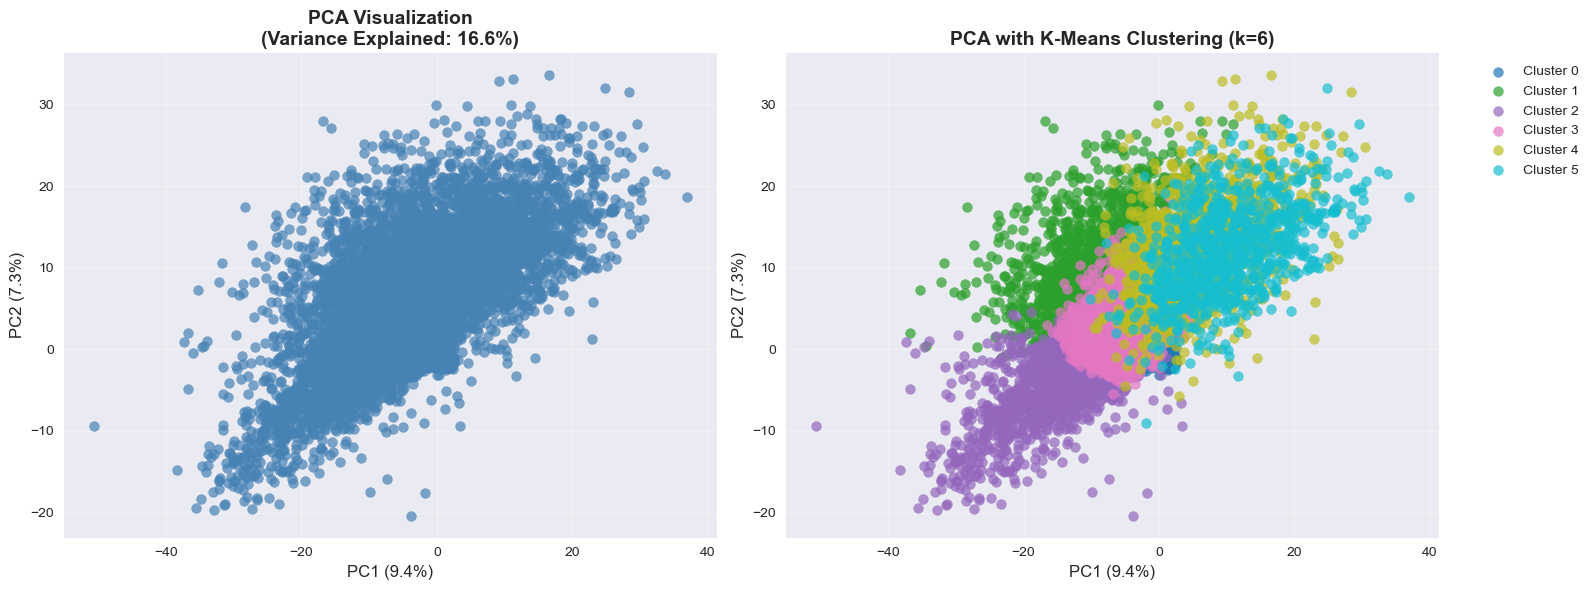

Creating labeled visualization...


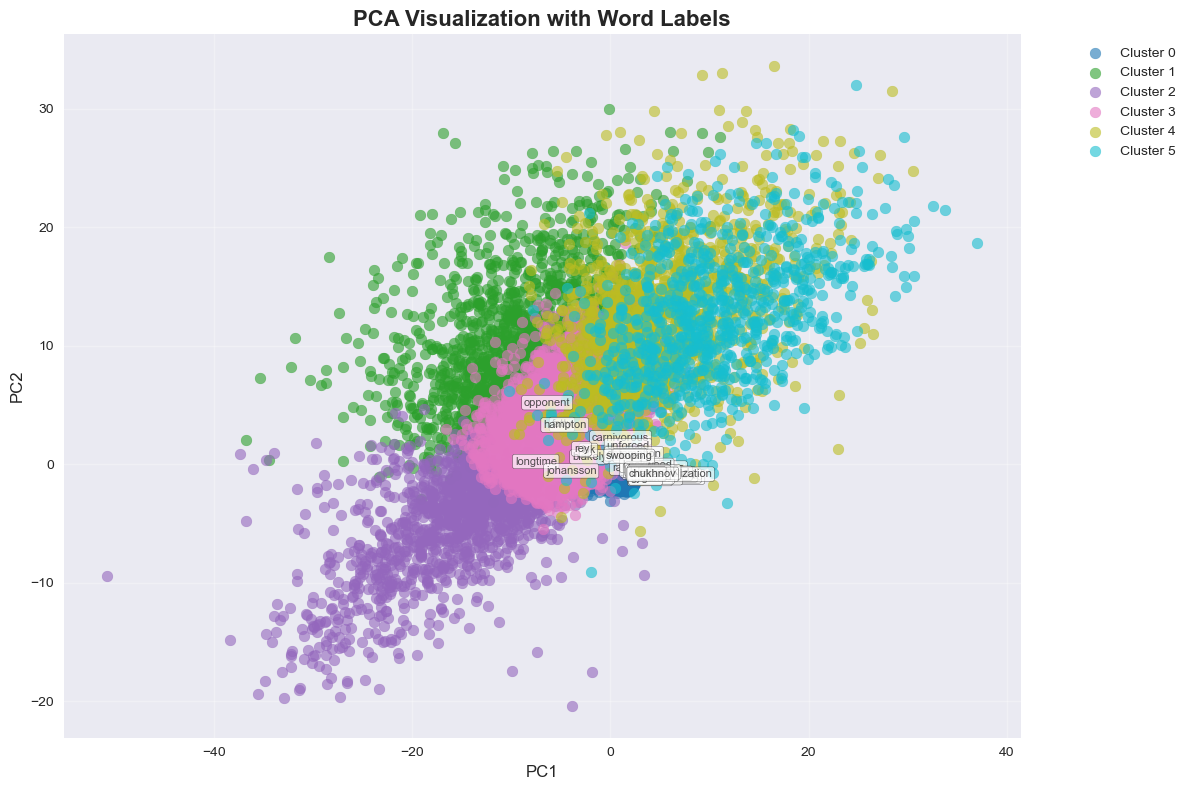


CLUSTER ANALYSIS

Cluster 0 (69261 words):
------------------------------
Sample words: luck, awhile, shawshank, jerker, quicker, spartan, flushed, yash, bluth, abnormal, preconception, disliking, gaffe, lucid, breakup
... and 69246 more words

Cluster 1 (1871 words):
------------------------------
Sample words: man, woman, girl, around, set, family, shot, turn, war, go, boy, help, black, death, house
... and 1856 more words

Cluster 2 (1450 words):
------------------------------
Sample words: performance, play, role, cast, star, young, played, job, wife, john, lead, excellent, name, playing, brother
... and 1435 more words

Cluster 3 (16021 words):
------------------------------
Sample words: american, act, become, english, mention, british, french, dance, among, student, brought, stage, lover, became, project
... and 16006 more words

Cluster 4 (1491 words):
------------------------------
Sample words: character, story, scene, also, plot, acting, work, director, world, quite, action

In [59]:
# After you have your word_embeddings and words ready

pca_df, pca_model, kmeans_model = quick_pca_analysis(
    word_embeddings.vectors,  # word2vec vectors  
    words,                    # words list
    n_clusters=6,            # 6 clusters
    show_labels=True,        # Show word labels 
    n_labels=40              
)

4. Model Building
= 

4.1 Unsupervied Models
=

In [66]:
#tokenized_corpus[:2]

In [61]:
# We will use gensim library for topic modeling
# Import corpora module for document processing
from gensim import corpora
my_dictionary = corpora.Dictionary(tokenized_corpus)
my_dictionary

In [63]:
# Import LdaMulticore for parallel LDA implementation
from gensim.models.ldamulticore import LdaMulticore
# Import matplotlib for visualization
import matplotlib.pyplot as plt

In [65]:
print(len(my_dictionary))
print(my_dictionary)

90963
Dictionary<90963 unique tokens: ['accustomed', 'agenda', 'agreement', 'appeal', 'around']...>


In [67]:
# Print 10 random items from the dictionary to understand its structure
print("10 random items from the dictionary:")
import random
random_ids = random.sample(list(my_dictionary.keys()), 10)
for word_id in random_ids:
    print(f"Word ID {word_id}: {my_dictionary[word_id]}")

10 random items from the dictionary:
Word ID 19007: livia
Word ID 18633: embezzler
Word ID 89275: mysportscomplex
Word ID 5535: certificate
Word ID 37026: heusen
Word ID 36022: wilkie
Word ID 2145: casting
Word ID 9847: ceremonial
Word ID 86950: samoura
Word ID 70828: voyna


In [69]:
# This is creating a "bag-of-words" representation of your processed texts using the Gensim library.
my_corpus = [my_dictionary.doc2bow(text) for text in tokenized_corpus]
#my_corpus[:2]

In [71]:
num_topics = 10  # Number of topics to be extracted
my_passes = 10 # Number of my_passes of the corpus through the model during training. More my_passes means better accuracy but longer runtime
workers = 4  # Number of worker processes for parallel computing

In [73]:
lda_model = LdaMulticore(
    corpus=my_corpus, # The document-term list we created earlier
    id2word=my_dictionary, # Maps word IDs to actual words for interpretable output
    num_topics=num_topics, # Number of topics to extract
    passes=my_passes, # Number of training my_passes through the corpus
    workers=workers, # Number of parallel processes to use
    alpha='symmetric', # Topic distribution prior - 'symmetric' gives equal probability to all topics initially
    eta='auto' # Word distribution prior (influences how words are distributed across topics). 'auto' lets the model learn optimal word weights. β in notes.
)

In [74]:
from gensim.models.coherencemodel import CoherenceModel
coherence_model_lda = CoherenceModel(model=lda_model, texts=tokenized_corpus, dictionary=my_dictionary, coherence='c_v')
coherence_score = coherence_model_lda.get_coherence()
print(f"Coherence Score: {coherence_score:.4f}")

Coherence Score: 0.3041


In [77]:
perplexity = lda_model.log_perplexity(my_corpus)
print(f"Perplexity: {perplexity:.4f}")

Perplexity: -8.3865


In [79]:
# Topic-term weight statistics
import numpy as np

# Get topic-term matrix
topic_term_matrix = lda_model.get_topics()
print(topic_term_matrix.shape)

# Calculate statistics about topic-term weights
topic_term_stats = {
    'mean': np.mean(topic_term_matrix),
    'std': np.std(topic_term_matrix),
    'min': np.min(topic_term_matrix),
    'max': np.max(topic_term_matrix)
}

print("\nTopic-Term Weight Statistics:")
for stat, value in topic_term_stats.items():
    print(f"{stat.capitalize()}: {value:.6f}")

(10, 90963)

Topic-Term Weight Statistics:
Mean: 0.000011
Std: 0.000144
Min: 0.000000
Max: 0.043108


In [81]:
top_n = 30
top_words = set()

# Collect top-N words across all topics
for topic in lda_model.get_topics():
    top_indices = topic.argsort()[-top_n:][::-1]
    top_words.update(top_indices)

# Convert to sorted list
top_words = sorted(list(top_words))

# Slice topic_term_matrix to include only top-N words
reduced_topic_matrix = topic_term_matrix[:, top_words]

# Now compute distinctiveness as before
topic_similarities = np.zeros((num_topics, num_topics))
for i in range(num_topics):
    for j in range(num_topics):
        if i != j:
            similarity = np.dot(reduced_topic_matrix[i], reduced_topic_matrix[j]) / (
                np.linalg.norm(reduced_topic_matrix[i]) * np.linalg.norm(reduced_topic_matrix[j])
            )
            topic_similarities[i, j] = similarity

avg_similarities = np.mean(topic_similarities, axis=1)
topic_distinctiveness = 1 - avg_similarities

print("\nTopic Distinctiveness (higher is better):")
for i, d in enumerate(topic_distinctiveness):
    print(f"Topic {i+1}: {d:.4f}")
print(f"Average Topic Distinctiveness: {np.mean(topic_distinctiveness):.4f}")


Topic Distinctiveness (higher is better):
Topic 1: 0.5135
Topic 2: 0.6064
Topic 3: 0.5049
Topic 4: 0.4317
Topic 5: 0.3986
Topic 6: 0.4095
Topic 7: 0.4141
Topic 8: 0.4464
Topic 9: 0.4412
Topic 10: 0.4228
Average Topic Distinctiveness: 0.4589


In [83]:
# Print the topics
print("\nGensim LDA Topics:")
for idx, topic in lda_model.print_topics(-1):
    print(f"Topic {idx+1}: {topic}")


Gensim LDA Topics:
Topic 1: 0.042*"movie" + 0.013*"like" + 0.012*"one" + 0.011*"bad" + 0.009*"would" + 0.009*"good" + 0.009*"even" + 0.008*"really" + 0.008*"film" + 0.007*"time"
Topic 2: 0.022*"show" + 0.011*"episode" + 0.011*"series" + 0.009*"one" + 0.008*"character" + 0.007*"comedy" + 0.006*"like" + 0.005*"time" + 0.005*"first" + 0.005*"get"
Topic 3: 0.011*"song" + 0.009*"music" + 0.008*"film" + 0.008*"one" + 0.008*"version" + 0.008*"musical" + 0.006*"great" + 0.005*"dance" + 0.005*"time" + 0.004*"movie"
Topic 4: 0.012*"film" + 0.010*"life" + 0.008*"character" + 0.007*"story" + 0.007*"one" + 0.006*"love" + 0.006*"family" + 0.005*"performance" + 0.005*"man" + 0.005*"woman"
Topic 5: 0.017*"film" + 0.007*"one" + 0.006*"good" + 0.005*"role" + 0.005*"man" + 0.004*"well" + 0.004*"story" + 0.004*"great" + 0.004*"western" + 0.004*"time"
Topic 6: 0.010*"film" + 0.009*"one" + 0.007*"get" + 0.005*"like" + 0.005*"scene" + 0.004*"guy" + 0.004*"movie" + 0.003*"man" + 0.003*"killer" + 0.003*"horro

In [85]:
#!pip install pyLDAvis

In [87]:
import pyLDAvis
import pyLDAvis.gensim_models as gensimvis

# Prepare the visualization
vis_data = gensimvis.prepare(lda_model, my_corpus, my_dictionary)

# Set the figure size for better visualization
pyLDAvis.enable_notebook()

# Display the interactive visualization
pyLDAvis.display(vis_data)

In [89]:
# Get 10 random documents and print their topics
import random
import numpy as np

# Select 10 random document indices
random_doc_indices = random.sample(range(len(my_corpus)), 10)

print("\nTopic Distribution for 10 Random Documents:")
print("-" * 50)

for idx in random_doc_indices:
    # Get the document's topic distribution
    doc_topics = lda_model.get_document_topics(my_corpus[idx])

    # Sort topics by probability (highest first)
    doc_topics = sorted(doc_topics, key=lambda x: x[1], reverse=True)

    # Get the original text (if available)
    original_text = df_review.iloc[idx]

    print(f"\nDocument {idx}: \"{original_text}\"")
    print("Topic Distribution:")

    for topic_id, prob in doc_topics[:3]:
        # Get the top words for this topic
        topic_words = lda_model.show_topic(topic_id, topn=5)
        words = ", ".join([word for word, _ in topic_words])

        # Format the probability as a percentage
        prob_percent = prob * 100

        print(f"  Topic {topic_id+1}: {prob_percent:.2f}% ({words})")



Topic Distribution for 10 Random Documents:
--------------------------------------------------

Document 42251: "usual disclaimer give star rating movie harmless bad low budget silly although may deserve film often funny get rated based sheerly entertainment value representation exemplary film artistry film fit model perfectly mexican monster movie riddled voice narrative extremely weak special effect makeup bad acting sometimes quite entertaining film almost silly alien predator script half slick alien predator might get want see commit plot ridiculous deliciously convoluted read far must really want know group remarkably unscientific scientist comprise main character hero sort one course mad quite perverse mad scientist invents laughable nuclear powered robot look bit like tin man wizard human face inexplicably located inside head aztec mummy discovered iscientist whose wife happens aztec princess past life ask pitted robot big climax fight scene alone enough put stoic movie watcher

4.2 Supervied learning 
= 

Task 1 
=

# (B) One DL model:

In [71]:
#pip install sentence_transformers

In [72]:
#pip install tf-keras

In [91]:
from sentence_transformers import SentenceTransformer
import os
import torch
import os
if torch.cuda.device_count()>0:
    my_device = "cuda"
    print(f"You have {torch.cuda.device_count()} GPUs available.")
else:
    my_device = "cpu"
    print("You have no GPUs available. Running on CPU.")

<frozen importlib._bootstrap>:488: DeprecationWarning: Type google.protobuf.pyext._message.ScalarMapContainer uses PyType_Spec with a metaclass that has custom tp_new. This is deprecated and will no longer be allowed in Python 3.14.
<frozen importlib._bootstrap>:488: DeprecationWarning: Type google.protobuf.pyext._message.MessageMapContainer uses PyType_Spec with a metaclass that has custom tp_new. This is deprecated and will no longer be allowed in Python 3.14.



You have 1 GPUs available.


In [100]:
#pip install huggingface_hub[hf_xet]

In [93]:
os.environ.setdefault('HF_TOKEN', '')  # set HF_TOKEN in your environment
os.environ['HF_HOME'] = './huggingface_cache'
embeddings_model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2',
                                       token=os.environ["HF_TOKEN"],
                                       cache_folder=os.environ["HF_HOME"],
                                       device=my_device)

In [95]:
df_review = df_review.to_frame()

In [97]:
df_sent = df_sent.to_frame()

In [162]:

from sklearn.model_selection import train_test_split

X = df_review['review']  
y = df_sent['sentiment'] 

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

y_train = y_train.map({'positive': 1, 'negative': 0}).astype(np.float32)
y_test = y_test.map({'positive': 1, 'negative': 0}).astype(np.float32)

In [164]:
# Convert text into  embeddings

X_train_emb = embeddings_model.encode(X_train.reset_index(drop=True), convert_to_numpy=True, show_progress_bar=False)
X_test_emb = embeddings_model.encode(X_test.reset_index(drop=True), convert_to_numpy=True, show_progress_bar=False)


In [166]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Convert to proper dtype
X_train_emb = np.array(X_train_emb, dtype=np.float32)
y_train = np.array(y_train, dtype=np.float32)

from tensorflow.keras import Input

model = Sequential([
    Input(shape=(X_train_emb.shape[1],)),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)


history = model.fit(X_train_emb, y_train, validation_split=0.2, epochs=15, batch_size=32, callbacks=[early_stop])


Epoch 1/15
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7661 - loss: 0.4736 - val_accuracy: 0.8073 - val_loss: 0.4136
Epoch 2/15
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8254 - loss: 0.3895 - val_accuracy: 0.8279 - val_loss: 0.3848
Epoch 3/15
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8273 - loss: 0.3793 - val_accuracy: 0.8265 - val_loss: 0.3827
Epoch 4/15
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8448 - loss: 0.3549 - val_accuracy: 0.8281 - val_loss: 0.3817
Epoch 5/15
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8525 - loss: 0.3397 - val_accuracy: 0.8305 - val_loss: 0.3796
Epoch 6/15
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8570 - loss: 0.3279 - val_accuracy: 0.8278 - val_loss: 0.3836
Epoch 7/15
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8731 - loss: 0.2997 - val_accuracy: 0.8314 - val_loss: 0.3851
Epoch 8/15
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8790 - loss: 0.2836 - 

In [170]:
# Predict probabilities
y_pred_probs = model.predict(X_test_emb)

# Convert probabilities to binary class labels
y_pred = (y_pred_probs > 0.5).astype(int).flatten()

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive']))


313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 649us/step

Classification Report:
              precision    recall  f1-score   support

    Negative       0.82      0.86      0.84      5000
    Positive       0.86      0.81      0.83      5000

    accuracy                           0.84     10000
   macro avg       0.84      0.84      0.84     10000
weighted avg       0.84      0.84      0.84     10000



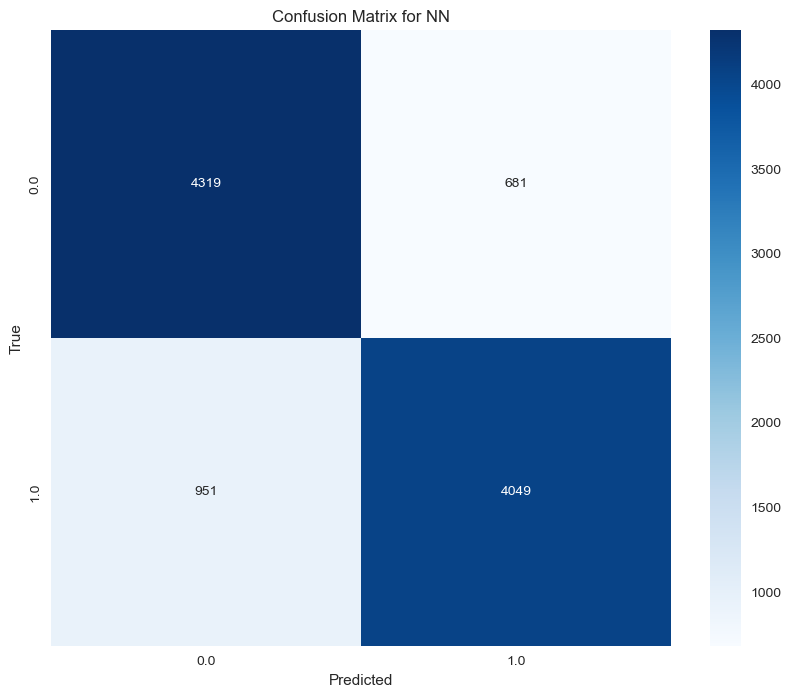

In [176]:
# Confusion Matrix
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=sorted(set(y_test)),
            yticklabels=sorted(set(y_test)))
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix for NN')
plt.show()





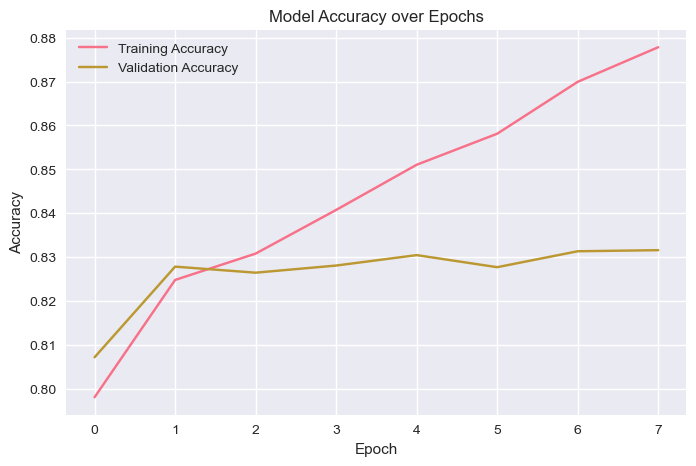

In [168]:

# Plot training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()


# 4.2 (A) Classic ML model

In [105]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(df_review, df_sent, test_size=0.2, random_state=42)
# Tokenize the text data for Word2Vec
tokenized_train = X_train['review'].astype(str).apply(lambda x: x.split()).tolist()
tokenized_test = X_test['review'].astype(str).apply(lambda x: x.split()).tolist()

In [107]:
from gensim.models import Word2Vec
# Train Word2Vec model
# Parameters:
# - vector_size: Dimensionality of the word vectors
# - window: Maximum distance between the current and predicted word
# - min_count: Ignores words with frequency lower than this
# - workers: Number of threads to run in parallel
# - sg: Training algorithm: 1 for skip-gram; 0 for CBOW
print("Training Word2Vec model...")
w2v_model = Word2Vec(
    sentences=tokenized_train,
    vector_size=384,
    window=5,
    min_count=2,
    workers=4,
    sg=1,
    seed=42
)


Training Word2Vec model...


In [109]:
print(f"Vocabulary size: {len(w2v_model.wv.key_to_index)}")

Vocabulary size: 50505


In [111]:
print(f"Training Word2Vec matrix shape: {X_train.shape}")
print(f"Testing Word2Vec matrix shape: {X_test.shape}")

Training Word2Vec matrix shape: (40000, 1)
Testing Word2Vec matrix shape: (10000, 1)


In [113]:
# Function to create document vectors by averaging word vectors
def document_vector(doc, model):
    # Filter words that are in the model vocabulary
    doc_words = [word for word in doc if word in model.wv]
    if len(doc_words) == 0:
        # Return zeros if no words are in vocabulary
        return np.zeros(model.vector_size)
    # Return the mean of all word vectors in the document
    return np.mean([model.wv[word] for word in doc_words], axis=0)

In [115]:
# Create document vectors for training and testing sets
X_train = np.array([document_vector(doc, w2v_model) for doc in tokenized_train])
X_test = np.array([document_vector(doc, w2v_model) for doc in tokenized_test])

In [117]:
len(X_train[0])

384

In [119]:
print(f"Training Word2Vec matrix shape: {X_train.shape}")
print(f"Testing Word2Vec matrix shape: {X_test.shape}")

Training Word2Vec matrix shape: (40000, 384)
Testing Word2Vec matrix shape: (10000, 384)


In [121]:
# Explore some word similarities
try:
    # Find words most similar
    print("\nWords most similar to 'episode':")
    for word, similarity in w2v_model.wv.most_similar('episode', topn=5):
        print(f"{word}: {similarity:.4f}")
except KeyError:
    print("Word 'delicious' not in vocabulary. Try another common word.")


Words most similar to 'episode':
season: 0.6734
farscape: 0.6208
smallville: 0.6125
cancellation: 0.5956
tng: 0.5929


In [123]:
from sentence_transformers import SentenceTransformer
import os
import torch
import os
if torch.cuda.device_count()>0:
    my_device = "cuda"
    print(f"You have {torch.cuda.device_count()} GPUs available.")
else:
    my_device = "cpu"
    print("You have no GPUs available. Running on CPU.")

You have 1 GPUs available.


In [125]:
'''
os.environ.setdefault('HF_TOKEN', '')  # set HF_TOKEN in your environment
os.environ['HF_HOME'] = './huggingface_cache'
embeddings_model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2',
                                       token=os.environ["HF_TOKEN"],
                                       cache_folder=os.environ["HF_HOME"],
                                       device=my_device)
'''

In [127]:
print(f"Training Word2Vec matrix shape: {X_train.shape}")
print(f"Testing Word2Vec matrix shape: {X_test.shape}")

Training Word2Vec matrix shape: (40000, 384)
Testing Word2Vec matrix shape: (10000, 384)


In [129]:
# Import necessary libraries
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_val_score

# Initialize the Logistic Regression model
# Use 'multinomial' solver for multi-class classification
lr_model = LogisticRegression(
    multi_class='multinomial',  # Multinomial for multi-class problems
    solver='lbfgs',             # Efficient solver for multinomial logistic regression
    max_iter=1000,              # Increase max iterations to ensure convergence
    random_state=42,            # For reproducibility
    n_jobs=-1                   # Use all available cores
)

In [131]:
# Train the model
print("Training Logistic Regression model...")
lr_model.fit(X_train, y_train)

Training Logistic Regression model...


D:\AnacondaNav\Lib\site-packages\sklearn\utils\validation.py:1339: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
D:\AnacondaNav\Lib\site-packages\sklearn\linear_model\_logistic.py:1237: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, binary problems will be fit as proper binary  logistic regression models (as if multi_class='ovr' were set). Leave it to its default value to avoid this warning.
  warnings.warn(


LogisticRegression(max_iter=1000, multi_class='multinomial', n_jobs=-1,
                   random_state=42)

In [132]:
# Make predictions
y_pred = lr_model.predict(X_test)

# Evaluate the model
print("\nLogistic Regression Model Evaluation:")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")


Logistic Regression Model Evaluation:
Accuracy: 0.8837


In [135]:
# Display detailed classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

    negative       0.89      0.88      0.88      4961
    positive       0.88      0.89      0.89      5039

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000



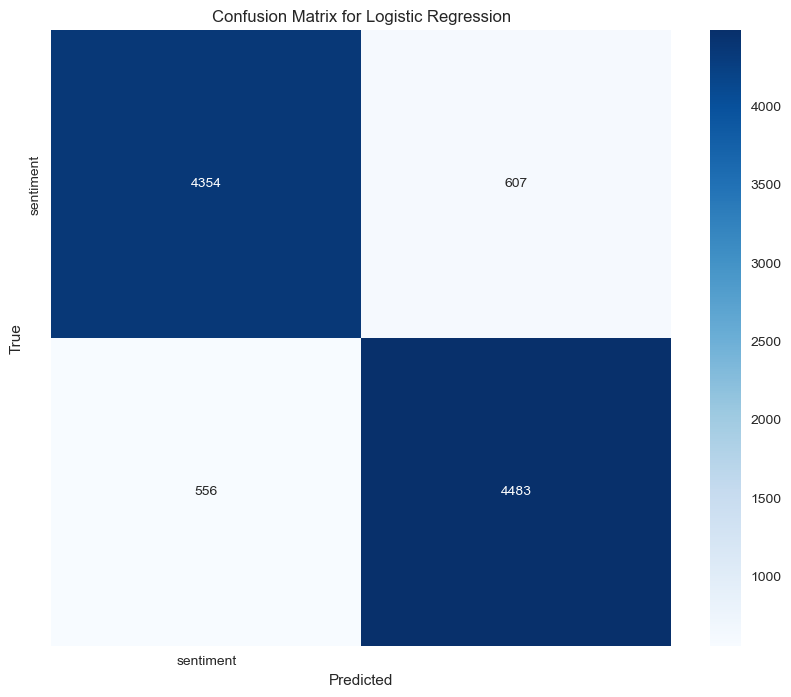

In [137]:
# Confusion Matrix
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=sorted(set(y_test)),
            yticklabels=sorted(set(y_test)))
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix for Logistic Regression')
plt.show()

SVM 

Training SVM...


D:\AnacondaNav\Lib\site-packages\sklearn\utils\validation.py:1339: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


Making predictions...
Training Accuracy: 0.891
Test Accuracy: 0.883

Classification Report:
              precision    recall  f1-score   support

    negative       0.89      0.88      0.88      4961
    positive       0.88      0.89      0.88      5039

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000



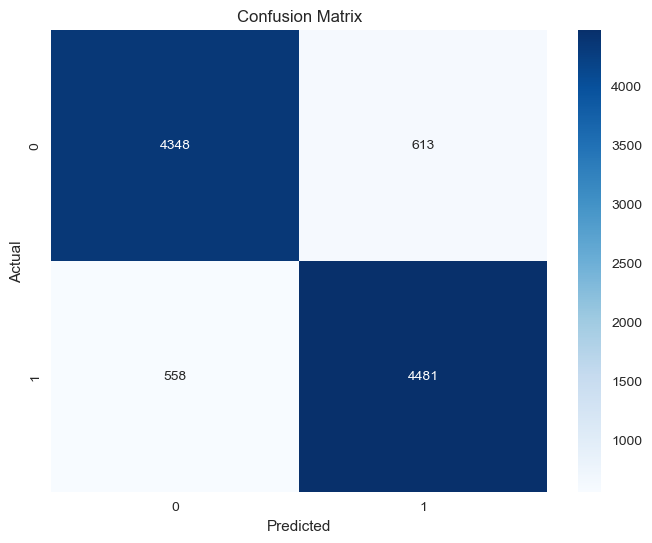

In [139]:
# Simple SVM Sentiment Analysis
from sklearn.svm import SVC
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Step 2: Train SVM model
print("Training SVM...")
svm_model = SVC(kernel='rbf', C=1, random_state=42)
svm_model.fit(X_train, y_train)

# Step 3: Make predictions
print("Making predictions...")
y_pred = svm_model.predict(X_test)

# Step 4: Evaluate results
train_accuracy = svm_model.score(X_train, y_train)
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Training Accuracy: {train_accuracy:.3f}")
print(f"Test Accuracy: {test_accuracy:.3f}")

# Step 5: Show detailed results
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Step 6: Plot confusion matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


# 4.2 Explainable AI

In [107]:
#pip install lime

In [112]:
from lime.lime_text import LimeTextExplainer
from sklearn.pipeline import make_pipeline
import random

# 1. Get original text (untokenized string) from test set
idx = random.randint(0, len(X_test) - 1)
example_tokens = tokenized_test[idx]
example_text = " ".join(example_tokens)

# 2. Define a custom prediction function using your Word2Vec model
def predict_proba_w2v(texts):
    vectors = []
    for text in texts:
        tokens = text.split()
        vectors.append(document_vector(tokens, w2v_model))
    return lr_model.predict_proba(vectors)

# 3. Run LIME
explainer = LimeTextExplainer(class_names=['negative', 'positive'])
exp = explainer.explain_instance(example_text, predict_proba_w2v, num_features=10)

# 4. Display
print(f"\nText:\n{example_text}")
print(f"True Label: {y_test.iloc[idx]}")
exp.show_in_notebook(text=example_text)



Text:
looking eye candy may enjoy sky captain sky captain video game injected live performer visials nice interesting look entire movie saying visuals thing good sky captain ten minute knew watching one worse movie time hoping movie would get better never achieved degree interest thirty minute urge walk kept growing growing movie seen probably five time number yet second movie felt like walking entire life acting none three main performer pitiful jude law also movie wanted walk awful title role would rather sit ben affleck gigli watch law paltrow try hard campy backfire face last article read said paltrow thinking staying home mother rather acting performance would applaud decision story soap opera better written story behind sky captain start bad get continually worse progress directing none everything put special effect story acting directing suffer greatly even phantom menace better acting saying great deal would give movie avoid paying theatre price wait video release
True Label: 

D:\AnacondaNav\Lib\site-packages\lime\explanation.py:194: DeprecationWarning: Importing display from IPython.core.display is deprecated since IPython 7.14, please import from IPython display
  from IPython.core.display import display, HTML


# Task 2 RAG 

# Task 3 UI development